# Short-Term Rental Market Intelligence
**BUDT 758J | Spring 2026 | Team 9: Aditya Agarwal, Anaushka Taneja, Pratinav Bomireddy, Ioannis Mimigiannis, Nikhil Nagesh**

---

# PART 1 — Data Collection & Master Build

This section pulls all external data sources, processes Airbnb listings and reviews, loads crime data, and merges everything into a single master table saved as `master_db_tractlevel.csv`.

**If you already have `master_db_tractlevel.csv`, skip directly to Part 2.**


## Install Dependencies
Run once when setting up a new environment. Comment out after first run.

In [1]:
# Install packages if you haven't already
# Run this cell once, then you can skip it
# !pip install osmnx geopandas pandas requests census partridge tqdm

## Imports
All libraries required for Part 1 and Part 2 are imported here.

In [ ]:
import os
import time
import requests
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.geometry import Point
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm

os.makedirs('./data', exist_ok=True)
warnings.filterwarnings('ignore')
print('All imports successful!')


## Configuration
Set your Census API key here.

In [3]:
# ============================================================
# PASTE YOUR CENSUS API KEY HERE
# Get one free at: https://api.census.gov/data/key_signup.html
# ============================================================
CENSUS_API_KEY = "fbadf937e786f3b5a42ea7ce420837f4008f8293"

# Cities we are analyzing
# Scope narrowed to Boston and San Francisco for this project
# Each entry: city name for OSMnx | state FIPS | county FIPS codes
CITIES = {
    "boston": {"osm_name": "Boston, Massachusetts, USA", "state": "25", "counties": ["025"]},
    "sf":     {"osm_name": "San Francisco, California, USA", "state": "06", "counties": ["075"]},
}

print("Config ready. Cities:", list(CITIES.keys()))

Config ready. Cities: ['boston', 'sf']


---
## Section 1 — External Data Collection
Pull OSM amenities, Census ACS demographics, and EPA walkability scores. All aggregated to census tract level.


### 1.1 Census Tract Boundaries
Download Census TIGER/Line shapefiles for Boston (MA) and San Francisco (CA). These polygon boundaries are needed for all spatial joins.

In [4]:
# Download Census TIGER/Line tract shapefiles for each state
# These come directly from the Census Bureau — no API key needed

all_tracts = []

# Get the unique states we need
states_needed = set(cfg["state"] for cfg in CITIES.values())

for state_fips in states_needed:
    print(f"Downloading tracts for state {state_fips}...")
    
    url = f"https://www2.census.gov/geo/tiger/TIGER2023/TRACT/tl_2023_{state_fips.zfill(2)}_tract.zip"
    gdf = gpd.read_file(url)   # geopandas reads directly from URL
    
    # Only keep the counties we care about
    counties_in_state = []
    for cfg in CITIES.values():
        if cfg["state"] == state_fips:
            counties_in_state.extend(cfg["counties"])
    
    gdf = gdf[gdf["COUNTYFP"].isin(counties_in_state)]
    all_tracts.append(gdf)
    print(f"  -> {len(gdf)} tracts loaded for state {state_fips}")

# Combine all states into one GeoDataFrame
tract_gdf = pd.concat(all_tracts, ignore_index=True)
tract_gdf = gpd.GeoDataFrame(tract_gdf, geometry="geometry", crs="EPSG:4326")

print(f"\nTotal tracts across all cities: {len(tract_gdf)}")
tract_gdf[["GEOID", "NAMELSAD", "COUNTYFP", "STATEFP"]].head()

  -> 244 tracts loaded for state 06
  -> 235 tracts loaded for state 25

Total tracts across all cities: 479


,GEOID,NAMELSAD,COUNTYFP,STATEFP
0,06075020602,Census Tract 206.02,075,06
1,06075012202,Census Tract 122.02,075,06
2,06075017102,Census Tract 171.02,075,06
3,06075012302,Census Tract 123.02,075,06
4,06075016801,Census Tract 168.01,075,06


### 1.2 OpenStreetMap — Amenity Counts per Tract
Query OSM for restaurants, cafes, grocery stores, bus stops, subway stations, and more. Spatially join POIs to tracts and count per amenity type.

**Note:** This cell takes 30–60 minutes. Each city is saved as it completes so you can resume if interrupted.

In [5]:
# These are the amenity types we want to count per census tract
# Format: { column_name_in_output : OSM tag to search for }

AMENITY_TAGS = {
    "restaurants":  {"amenity": ["restaurant", "fast_food"]},
    "cafes":        {"amenity": "cafe"},
    "bars":         {"amenity": ["bar", "pub"]},
    "grocery":      {"shop": ["supermarket", "grocery", "convenience"]},
    "pharmacy":     {"amenity": "pharmacy"},
    "hospital":     {"amenity": ["hospital", "clinic"]},
    "laundry":      {"shop": ["laundry", "dry_cleaning"]},
    "shopping":     {"shop": ["mall", "department_store", "clothes"]},
    "bus_stop":     {"highway": "bus_stop"},
    "subway":       {"railway": ["subway_entrance", "station"]},
}

print("Amenity types to pull:", list(AMENITY_TAGS.keys()))

Amenity types to pull: ['restaurants', 'cafes', 'bars', 'grocery', 'pharmacy', 'hospital', 'laundry', 'shopping', 'bus_stop', 'subway']


In [6]:
# Pull OSM data for all cities
# We save each city to a CSV as we go

all_pois = []   # will hold all POIs from all cities

for city_key, cfg in CITIES.items():
    save_path = f"./data/osm_{city_key}_raw.csv"
    
    # Skip if we already pulled this city
    if os.path.exists(save_path):
        print(f"[{city_key}] Already done — loading from file")
        city_df = pd.read_csv(save_path)
        all_pois.append(city_df)
        continue
    
    print(f"\n[{city_key}] Pulling OSM data for: {cfg['osm_name']}")
    city_pois = []
    
    for amenity_name, tags in AMENITY_TAGS.items():
        try:
            # Pull all POIs of this type in the city
            gdf = ox.features_from_place(cfg["osm_name"], tags=tags)
            
            # Some POIs are polygons (e.g. hospital buildings) — convert to centroid points
            # Re-project to metric CRS first to avoid the geographic CRS warning
            gdf = gdf.to_crs(epsg=3857)               # project to metric (meters)
            gdf["geometry"] = gdf["geometry"].centroid # compute centroid in metric space
            gdf = gdf.to_crs(epsg=4326)               # convert back to lat/lon
            
            # Extract the lat/lon
            gdf["lat"] = gdf.geometry.y
            gdf["lon"] = gdf.geometry.x
            gdf["amenity_type"] = amenity_name
            gdf["city"] = city_key
            
            # Keep only the columns we need
            poi_df = gdf[["city", "amenity_type", "lat", "lon"]].reset_index(drop=True)
            city_pois.append(poi_df)
            
            print(f"  {amenity_name}: {len(poi_df)} POIs")
            time.sleep(1)   # wait 1 second between requests — be polite to OSM
            
        except Exception as e:
            # Some amenity types won't exist in every city — that's fine
            print(f"  {amenity_name}: skipped ({e})")
    
    if city_pois:
        city_df = pd.concat(city_pois, ignore_index=True)
        city_df.to_csv(save_path, index=False)
        all_pois.append(city_df)
        print(f"[{city_key}] Saved {len(city_df)} POIs to {save_path}")

# Combine all cities
osm_all = pd.concat(all_pois, ignore_index=True)
print(f"\nTotal POIs across all cities: {len(osm_all):,}")
osm_all.head()

[boston] Already done — loading from file
[sf] Already done — loading from file

Total POIs across all cities: 12,586


,city,amenity_type,lat,lon
0,boston,restaurants,42.365720,-71.029040
1,boston,restaurants,42.362337,-71.140823
2,boston,restaurants,42.348574,-71.089100
3,boston,restaurants,42.353749,-71.137594
4,boston,restaurants,42.361934,-71.070457


In [7]:
# Spatial join: figure out which census tract each POI falls in
# Then count how many POIs of each type are in each tract

# Convert POI list to a GeoDataFrame
osm_gdf = gpd.GeoDataFrame(
    osm_all,
    geometry=gpd.points_from_xy(osm_all["lon"], osm_all["lat"]),
    crs="EPSG:4326"
)

# Spatial join: assign each POI to a tract
joined = gpd.sjoin(osm_gdf, tract_gdf[["GEOID", "geometry"]], how="left", predicate="within")
joined = joined.dropna(subset=["GEOID"])   # drop any POIs that didn't land in a tract

# Count POIs per tract per amenity type
osm_counts = (
    joined
    .groupby(["GEOID", "amenity_type"])
    .size()
    .reset_index(name="count")
    .pivot_table(index="GEOID", columns="amenity_type", values="count", fill_value=0)
    .reset_index()
)

# Rename columns to make it clear these are OSM counts
osm_counts.columns = ["GEOID"] + [f"osm_{c}" for c in osm_counts.columns if c != "GEOID"]
osm_counts.columns.name = None

# Save
osm_counts.to_csv("./data/osm_amenities_by_tract.csv", index=False)
print(f"Saved! Shape: {osm_counts.shape}")
osm_counts.head()

Saved! Shape: (441, 11)


,GEOID,osm_bars,osm_bus_stop,osm_cafes,osm_grocery,osm_hospital,osm_laundry,osm_pharmacy,osm_restaurants,osm_shopping,osm_subway
0,06075010101,5.0,26.0,10.0,1.0,0.0,0.0,2.0,51.0,17.0,0.0
1,06075010102,2.0,3.0,5.0,1.0,0.0,1.0,0.0,6.0,0.0,0.0
2,06075010201,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,06075010202,3.0,12.0,5.0,3.0,0.0,1.0,0.0,12.0,4.0,0.0
4,06075010300,1.0,9.0,1.0,0.0,0.0,2.0,1.0,2.0,0.0,0.0


### 1.3 Census ACS — Socioeconomic Features
Pull 10 variables from the 2023 ACS 5-Year estimates via the Census Bureau API.

**Requires:** Census API key in the Configuration cell above.

In [8]:
# These are the Census variables we want
# Format: { Census variable code : readable column name }

ACS_VARS = {
    "B19013_001E": "median_household_income",
    "B25064_001E": "median_gross_rent",
    "B25077_001E": "median_home_value",
    "B01003_001E": "total_population",
    "B25001_001E": "total_housing_units",
    "B17001_002E": "population_below_poverty",
    "B08301_010E": "commute_by_transit",
    "B08301_001E": "total_commuters",
    "B25003_002E": "owner_occupied_units",
    "B25003_003E": "renter_occupied_units",
}

print("Variables to pull:", list(ACS_VARS.values()))

Variables to pull: ['median_household_income', 'median_gross_rent', 'median_home_value', 'total_population', 'total_housing_units', 'population_below_poverty', 'commute_by_transit', 'total_commuters', 'owner_occupied_units', 'renter_occupied_units']


In [9]:
KEY = "fbadf937e786f3b5a42ea7ce420837f4008f8293"
BASE = "https://api.census.gov/data/2023/acs/acs5"

# Variables to pull
VARS = "B19013_001E,B25064_001E,B25077_001E,B01003_001E,B25001_001E,B17001_002E,B08301_010E,B08301_001E,B25003_002E,B25003_003E"

# Readable names for each variable code
RENAME = {
    "B19013_001E": "median_household_income",
    "B25064_001E": "median_gross_rent",
    "B25077_001E": "median_home_value",
    "B01003_001E": "total_population",
    "B25001_001E": "total_housing_units",
    "B17001_002E": "population_below_poverty",
    "B08301_010E": "commute_by_transit",
    "B08301_001E": "total_commuters",
    "B25003_002E": "owner_occupied_units",
    "B25003_003E": "renter_occupied_units",
}

all_acs = []

for city_key, cfg in CITIES.items():
    state = cfg["state"]
    for county in cfg["counties"]:
        print(f"[{city_key}] Pulling state={state} county={county}...")
        
        url = f"{BASE}?get=NAME,{VARS}&for=tract:*&in=state:{state}+county:{county}&key={KEY}"
        r = requests.get(url)
        
        if r.status_code != 200:
            print(f"  ❌ Error {r.status_code} — skipping")
            continue
        
        data   = r.json()
        headers = data[0]   # first row = column names
        rows    = data[1:]  # rest = data
        
        df = pd.DataFrame(rows, columns=headers)
        df["city"] = city_key
        all_acs.append(df)
        print(f"  ✓ {len(df)} tracts returned")
        
        time.sleep(2)   # wait 2 seconds between each request

# Combine all cities
acs_raw = pd.concat(all_acs, ignore_index=True)
print(f"\nTotal tracts pulled: {len(acs_raw)}")
acs_raw.head()

[boston] Pulling state=25 county=025...
  ✓ 235 tracts returned
[sf] Pulling state=06 county=075...
  ✓ 244 tracts returned

Total tracts pulled: 479


,NAME,B19013_001E,B25064_001E,B25077_001E,B01003_001E,B25001_001E,B17001_002E,B08301_010E,B08301_001E,B25003_002E,B25003_003E,state,county,tract,city
0,Census Tract 1.01; Suffolk County; Massachusetts,151466,2625,1015600,1666,570,155,251,1055,134,418,25,025,000101,boston
1,Census Tract 1.02; Suffolk County; Massachusetts,79000,2189,545300,4023,1940,1062,569,2526,271,1555,25,025,000102,boston
2,Census Tract 2.01; Suffolk County; Massachusetts,114271,2724,880700,4332,1898,636,532,3015,505,1340,25,025,000201,boston
3,Census Tract 2.02; Suffolk County; Massachusetts,88625,2211,837300,3703,1568,822,507,2221,467,995,25,025,000202,boston
4,Census Tract 3.01; Suffolk County; Massachusetts,131206,2754,822600,2718,1309,240,445,2002,482,741,25,025,000301,boston


In [10]:
acs = acs_raw.copy()

# Build the 11-digit GEOID
acs["GEOID"] = acs["state"].str.zfill(2) + acs["county"].str.zfill(3) + acs["tract"].str.zfill(6)

# Rename variable codes to readable names
acs = acs.rename(columns=RENAME)

# Convert to numbers, replace Census missing value codes with NaN
numeric_cols = list(RENAME.values())
for col in numeric_cols:
    if col in acs.columns:
        acs[col] = pd.to_numeric(acs[col], errors="coerce")
        acs[col] = acs[col].where(acs[col] >= 0, np.nan)  # -666666666 = missing

# Compute derived rates
acs["poverty_rate"]        = (acs["population_below_poverty"] / acs["total_population"] * 100).round(2)
acs["transit_commute_pct"] = (acs["commute_by_transit"] / acs["total_commuters"] * 100).round(2)
acs["renter_pct"]          = (acs["renter_occupied_units"] / acs["total_housing_units"] * 100).round(2)

# Keep only useful columns
keep = ["GEOID", "city"] + list(RENAME.values()) + ["poverty_rate", "transit_commute_pct", "renter_pct"]
acs = acs[[c for c in keep if c in acs.columns]].drop_duplicates(subset="GEOID")

# Save
acs.to_csv("./data/census_acs_by_tract.csv", index=False)
print(f"Saved! Shape: {acs.shape}")
acs.head()

Saved! Shape: (479, 15)


,GEOID,city,median_household_income,median_gross_rent,median_home_value,total_population,total_housing_units,population_below_poverty,commute_by_transit,total_commuters,owner_occupied_units,renter_occupied_units,poverty_rate,transit_commute_pct,renter_pct
0,25025000101,boston,151466.0,2625.0,1015600.0,1666,570,155,251,1055,134,418,9.30,23.79,73.33
1,25025000102,boston,79000.0,2189.0,545300.0,4023,1940,1062,569,2526,271,1555,26.40,22.53,80.15
2,25025000201,boston,114271.0,2724.0,880700.0,4332,1898,636,532,3015,505,1340,14.68,17.65,70.60
3,25025000202,boston,88625.0,2211.0,837300.0,3703,1568,822,507,2221,467,995,22.20,22.83,63.46
4,25025000301,boston,131206.0,2754.0,822600.0,2718,1309,240,445,2002,482,741,8.83,22.23,56.61


### 1.4 EPA Smart Location Database — Walkability & Transit
Filter the national EPA SLD to Boston and SF tracts and aggregate from block group to tract level.

**Manual download required:**
1. Go to: https://www.epa.gov/smartgrowth/smart-location-mapping
2. Download Smart Location Database v3.0 (CSV, ~180MB)
3. Save as `./data/epa_sld_national.csv`


In [11]:
# Load the EPA Smart Location Database
# This is a national file — we filter it down to our 6 cities

epa_path = "./data/epa_sld_national.csv"

if not os.path.exists(epa_path):
    print("File not found. Please download the EPA SLD CSV and save it to ./data/epa_sld_national.csv")
    print("Download: https://www.epa.gov/smartgrowth/smart-location-mapping")
else:
    print("Loading EPA SLD...")
    epa_raw = pd.read_csv(epa_path, low_memory=False)
    print(f"Loaded! Shape: {epa_raw.shape}")
    print("Columns:", list(epa_raw.columns[:15]), "...")  # preview first 15 columns

Loading EPA SLD...
Loaded! Shape: (220740, 117)
Columns: ['OBJECTID', 'GEOID10', 'GEOID20', 'STATEFP', 'COUNTYFP', 'TRACTCE', 'BLKGRPCE', 'CSA', 'CSA_Name', 'CBSA', 'CBSA_Name', 'CBSA_POP', 'CBSA_EMP', 'CBSA_WRK', 'Ac_Total'] ...


In [12]:
# Filter to only our target cities
# The SLD has STATEFP and COUNTYFP columns we can filter on

# Build the list of (state, county) pairs we want
target_state_county = []
for cfg in CITIES.values():
    for county in cfg["counties"]:
        target_state_county.append((int(cfg["state"]), int(county)))

# Filter
epa = epa_raw[
    epa_raw.apply(lambda row: (int(row["STATEFP"]), int(row["COUNTYFP"])) in target_state_county, axis=1)
].copy()

print(f"After filtering to our cities: {len(epa)} block groups")

# The SLD is at block group level (12-digit GEOID)
# We need to aggregate up to census tract level (11-digit GEOID)
# The first 11 digits of the block group GEOID = the tract GEOID
geoid_col = "GEOID20" if "GEOID20" in epa.columns else "GEOID10"
epa["GEOID"] = epa[geoid_col].astype(str).str.zfill(12).str[:11]

After filtering to our cities: 1227 block groups


In [13]:
# Pick the specific EPA columns we want for our model
# We dropped D1B (raw population density) because Census already gives us total_population
# and including both would be redundant (multicollinearity in the model)
# Full column reference: https://www.epa.gov/smartgrowth/smart-location-mapping

EPA_COLS = {
    "NatWalkInd": "epa_walkability_index",    # 1-20 walkability score — key feature
    "D2A_EPHHM":  "epa_land_use_mix",          # mix of residential + commercial land use
    "D3B":        "epa_intersection_density",  # street connectivity (intersections per sq mile)
    "D4A":        "epa_dist_to_transit_m",     # distance to nearest transit stop in meters
    "D4D":        "epa_transit_frequency",     # transit trips per hour near the tract
    "D5BR":       "epa_jobs_by_transit",       # jobs reachable within 45 min by transit
    "AutoOwn0":   "epa_zero_car_households",   # fraction of households with no car
}

# Keep only columns that exist in our dataset
available = {k: v for k, v in EPA_COLS.items() if k in epa.columns}

# Fix GEOID — pad to 12 digits first, then take first 11 for tract ID
# This was the bug causing EPA to not join — block group IDs weren't padded correctly
epa["GEOID"] = (
    epa["STATEFP"].astype(str).str.zfill(2) +
    epa["COUNTYFP"].astype(str).str.zfill(3) +
    epa["TRACTCE"].astype(str).str.zfill(6)
)

# Verify the fix
print(f"Sample EPA GEOID: {epa['GEOID'].iloc[0]}")  # should look like 25025000101

epa_subset = epa[["GEOID"] + list(available.keys())].copy()
epa_subset = epa_subset.rename(columns=available)

# Aggregate from block group to tract level (simple average across block groups)
epa_by_tract = (
    epa_subset
    .groupby("GEOID")
    .mean()
    .round(3)
    .reset_index()
)

# Save
epa_by_tract.to_csv("./data/epa_sld_by_tract.csv", index=False)
print(f"Saved! Shape: {epa_by_tract.shape}")
print(f"Sample GEOID after fix: {epa_by_tract['GEOID'].iloc[0]}")
print(f"Columns: {list(epa_by_tract.columns)}")
epa_by_tract.head()

Sample EPA GEOID: 06075012201
Saved! Shape: (401, 8)
Sample GEOID after fix: 06075010100
Columns: ['GEOID', 'epa_walkability_index', 'epa_land_use_mix', 'epa_intersection_density', 'epa_dist_to_transit_m', 'epa_transit_frequency', 'epa_jobs_by_transit', 'epa_zero_car_households']


,GEOID,epa_walkability_index,epa_land_use_mix,epa_intersection_density,epa_dist_to_transit_m,epa_transit_frequency,epa_jobs_by_transit,epa_zero_car_households
0,06075010100,19.583,0.837,438.186,37.550,439.117,558179.000,496.500
1,06075010200,17.778,0.688,412.570,195.803,530.869,541839.333,273.333
2,06075010300,16.444,0.429,283.882,235.143,831.507,502603.667,172.667
3,06075010400,18.167,0.726,432.330,272.248,909.717,602858.750,217.000
4,06075010500,18.083,0.786,379.765,230.000,834.702,730078.000,366.000


---
## Section 2 — Airbnb Listings & Reviews
Process Inside Airbnb listings and reviews. Aggregate listing features to tract level and load pre-computed VADER sentiment scores from the Colab BERTopic run.

**Note:** The `price` column is empty — Airbnb scrubs pricing from public data. We use `estimated_occupancy_l365d` as the demand proxy.


### 2.1 Load Listings & Reviews

In [14]:
listings = pd.read_csv("./data/listings_combined.csv", low_memory=False)
listings.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,city
0,3781,https://www.airbnb.com/rooms/3781,2.025120e+13,12/27/25,city scrape,Harborside-Walk to subway,Fully separate apartment in a two apartment bu...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,4804,...,4.85,4.89,NaN,NaN,1,1,0,0,0.21,Boston
1,5506,https://www.airbnb.com/rooms/5506,2.025120e+13,12/27/25,city scrape,** Fort Hill Inn Private! Minutes to center!**,**THE BEST Value in BOSTON!!*** PRIVATE GUEST ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,8229,...,4.58,4.77,STR-490093,NaN,11,11,0,0,0.69,Boston
2,6695,https://www.airbnb.com/rooms/6695,2.025120e+13,12/27/25,city scrape,"Fort Hill Inn *Sunny* 1 bedroom, condo duplex","Comfortable, Fully Equipped private apartment...",NaN,https://a0.muscache.com/pictures/38ac4797-e7a4...,8229,...,4.55,4.73,STR-491702,NaN,11,11,0,0,0.72,Boston
3,10811,https://www.airbnb.com/rooms/10811,2.025120e+13,12/27/25,city scrape,Bostons Best Rentals -Studio Prestigious Back Bay,Bostons Best Rentals offers a Stunning Back Ba...,NaN,https://a0.muscache.com/pictures/45735/27548f7...,38997,...,5.00,4.67,NaN,NaN,9,9,0,0,0.07,Boston
4,10813,https://www.airbnb.com/rooms/10813,2.025120e+13,12/27/25,city scrape,The Back Bay Nook -Brownstone in Prestigious ...,Stunning Back Bay furnished studio apartment. ...,NaN,https://a0.muscache.com/pictures/20b5b9c9-e1f4...,38997,...,5.00,4.83,NaN,NaN,9,9,0,0,0.07,Boston


In [15]:
reviews = pd.read_csv("./data/reviews_combined.csv", low_memory=False)
reviews.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments,city
0,3781,37776825,7/10/15,36059247,Greg,The apartment was as advertised and Frank was ...,Boston
1,3781,41842494,8/9/15,10459388,Tai,It was a pleasure to stay at Frank's place. Th...,Boston
2,3781,45282151,9/1/15,12264652,Damien,The apartment description is entirely faithful...,Boston
3,3781,49022647,9/30/15,41426327,Mike,Thoroughly enjoyed my time at Frank's home. Ha...,Boston
4,3781,52503327,10/30/15,15151513,Ivan,Great value for the money! This location has e...,Boston


### 2.2 Process Listings — Column Selection, Null Handling & Tract Join
Reduce 86 columns to 15 relevant features. Fill nulls using city-level medians. Spatially join listings to census tracts and aggregate to tract level.

In [16]:
cols_to_keep = [
    # Geography
    "id", "city", "latitude", "longitude", "neighbourhood_cleansed",
    # Property characteristics
    "property_type", "room_type", "accommodates", 
    "bathrooms", "bedrooms", "beds", "amenities",
    # Availability & occupancy
    "estimated_occupancy_l365d", "availability_365",
    # Review scores
    "review_scores_rating", "review_scores_location",
    # Demand signals
    "reviews_per_month", "number_of_reviews_ltm"
]

listings = listings[cols_to_keep].copy()
print(f"Shape after column selection: {listings.shape}")
print(f"\nNull counts per column:")
print(listings.isnull().sum())

Shape after column selection: (11241, 18)

Null counts per column:
id                              0
city                            0
latitude                        0
longitude                       0
neighbourhood_cleansed          0
property_type                   0
room_type                       0
accommodates                    0
bathrooms                    1808
bedrooms                      439
beds                         1847
amenities                       0
estimated_occupancy_l365d       0
availability_365                0
review_scores_rating         2495
review_scores_location       2496
reviews_per_month            2495
number_of_reviews_ltm           0
dtype: int64


In [17]:
# Drop rows missing critical geography — these are useless without location
listings = listings.dropna(subset=["latitude", "longitude", "neighbourhood_cleansed"])

# Property characteristics — fill with median (numeric) or mode (categorical)
# Bedrooms/bathrooms/beds: use median since outliers exist in Airbnb data
listings["bathrooms"] = listings["bathrooms"].fillna(listings["bathrooms"].median())
listings["bedrooms"]  = listings["bedrooms"].fillna(listings["bedrooms"].median())
listings["beds"]      = listings["beds"].fillna(listings["beds"].median())

# Accommodates should never really be null but just in case
listings["accommodates"] = listings["accommodates"].fillna(listings["accommodates"].median())

# Availability — fill with median
listings["availability_365"] = listings["availability_365"].fillna(listings["availability_365"].median())

# Occupancy — fill with median
listings["estimated_occupancy_l365d"] = listings["estimated_occupancy_l365d"].fillna(
    listings["estimated_occupancy_l365d"].median()
)

# Review scores — listings with no reviews will have null scores
# Fill with median WITHIN each city so we don't mix Boston and SF baselines
for col in ["review_scores_rating", "review_scores_location"]:
    listings[col] = listings.groupby("city")[col].transform(
        lambda x: x.fillna(x.median())
    )

# Demand signals — null here means no reviews yet, so fill with 0
listings["reviews_per_month"]      = listings["reviews_per_month"].fillna(0)
listings["number_of_reviews_ltm"]  = listings["number_of_reviews_ltm"].fillna(0)

# Amenities — null means no amenities listed, fill with empty list
listings["amenities"] = listings["amenities"].fillna("[]")

# Final check
print(f"Shape after null handling: {listings.shape}")
print(f"\nRemaining nulls:")
print(listings.isnull().sum())

Shape after null handling: (11241, 18)

Remaining nulls:
id                           0
city                         0
latitude                     0
longitude                    0
neighbourhood_cleansed       0
property_type                0
room_type                    0
accommodates                 0
bathrooms                    0
bedrooms                     0
beds                         0
amenities                    0
estimated_occupancy_l365d    0
availability_365             0
review_scores_rating         0
review_scores_location       0
reviews_per_month            0
number_of_reviews_ltm        0
dtype: int64


In [18]:
# First — spatial join listings to census tracts to get GEOID per listing
listings_gdf = gpd.GeoDataFrame(
    listings,
    geometry=gpd.points_from_xy(listings["longitude"], listings["latitude"]),
    crs="EPSG:4326"
)

# Join each listing to the tract it falls in
listings_with_tract = gpd.sjoin(
    listings_gdf, 
    tract_gdf[["GEOID", "geometry"]], 
    how="left", 
    predicate="within"
)
listings_with_tract = listings_with_tract.dropna(subset=["GEOID"])
print(f"Listings mapped to tracts: {len(listings_with_tract):,}")

# Now aggregate to tract level
tract_listings = listings_with_tract.groupby("GEOID").agg(
    
    # How many listings exist in this tract (supply/competition signal)
    total_listings           = ("id", "count"),
    
    # Breakdown by room type — what share of listings are entire homes vs private rooms
    entire_home_count        = ("room_type", lambda x: (x == "Entire home/apt").sum()),
    private_room_count       = ("room_type", lambda x: (x == "Private room").sum()),
    
    # Average property size
    avg_accommodates         = ("accommodates", "mean"),
    avg_bedrooms             = ("bedrooms", "mean"),
    
    # Demand signals — average across all listings in the tract
    avg_occupancy_rate       = ("estimated_occupancy_l365d", "mean"),
    avg_availability_365     = ("availability_365", "mean"),
    avg_reviews_per_month    = ("reviews_per_month", "mean"),
    total_reviews_ltm        = ("number_of_reviews_ltm", "sum"),
    
    # Quality signals
    avg_review_rating        = ("review_scores_rating", "mean"),
    avg_review_location      = ("review_scores_location", "mean"),

).reset_index()

# Compute share columns — more useful than raw counts
tract_listings["pct_entire_home"] = (
    tract_listings["entire_home_count"] / tract_listings["total_listings"] * 100
).round(2)

tract_listings["pct_private_room"] = (
    tract_listings["private_room_count"] / tract_listings["total_listings"] * 100
).round(2)

# Round numeric columns
numeric_cols = tract_listings.select_dtypes(include="number").columns
tract_listings[numeric_cols] = tract_listings[numeric_cols].round(3)

# Save
tract_listings.to_csv("./data/tract_listings_features.csv", index=False)
print(f"\nTract listings table saved! Shape: {tract_listings.shape}")
print(f"\nColumns: {list(tract_listings.columns)}")
tract_listings.head()

Listings mapped to tracts: 11,241

Tract listings table saved! Shape: (433, 14)

Columns: ['GEOID', 'total_listings', 'entire_home_count', 'private_room_count', 'avg_accommodates', 'avg_bedrooms', 'avg_occupancy_rate', 'avg_availability_365', 'avg_reviews_per_month', 'total_reviews_ltm', 'avg_review_rating', 'avg_review_location', 'pct_entire_home', 'pct_private_room']


,GEOID,total_listings,entire_home_count,private_room_count,avg_accommodates,avg_bedrooms,avg_occupancy_rate,avg_availability_365,avg_reviews_per_month,total_reviews_ltm,avg_review_rating,avg_review_location,pct_entire_home,pct_private_room
0,06075010101,140,80,29,5.721,1.279,23.100,246.229,0.364,367,4.852,4.917,57.14,20.71
1,06075010102,14,8,6,4.500,1.929,57.857,262.143,0.473,38,4.811,4.950,57.14,42.86
2,06075010201,15,14,1,3.400,1.667,83.133,102.400,0.511,64,4.926,4.943,93.33,6.67
3,06075010202,92,59,32,4.641,1.478,39.967,100.435,0.414,305,4.903,4.948,64.13,34.78
4,06075010300,40,27,13,3.500,1.550,96.525,187.300,0.685,228,4.841,4.928,67.50,32.50


### 2.3 Filter Neighborhood Reviews
Filter 640K reviews down to neighborhood-relevant ones for the BERTopic NLP pipeline:
1. Keep only reviews from 2022 onwards
2. Drop null comments
3. Keyword filter — reviews mentioning location, transit, walkability, nearby amenities

The resulting CSV is uploaded to Colab for BERTopic + VADER processing.


In [19]:
# ============================================================
# Step 1 — Filter to recent reviews only (2022 onwards)
# Neighborhoods change over time, older reviews may not 
# reflect current conditions
# ============================================================
reviews["date"] = pd.to_datetime(reviews["date"], format="mixed")
reviews_recent = reviews[reviews["date"] >= "2022-01-01"].copy()

print(f"Total reviews: {len(reviews):,}")
print(f"Reviews from 2022 onwards: {len(reviews_recent):,}")
print(f"Dropped: {len(reviews) - len(reviews_recent):,}")

# ============================================================
# Step 2 — Drop nulls in comments column
# ============================================================
reviews_recent = reviews_recent.dropna(subset=["comments"])
print(f"After dropping null comments: {len(reviews_recent):,}")

# ============================================================
# Step 3 — Keyword filter for neighborhood-related reviews
# Broad filter — captures explicit AND implicit location mentions
# ============================================================
neighborhood_keywords = [
    # Explicit neighborhood words
    "neighborhood", "neighbourhood", "area", "location", "located",
    # Proximity / walkability
    "walk", "walkable", "walking distance", "nearby", "close to",
    "minutes away", "steps from", "blocks from",
    # Transit
    "subway", "metro", "bus", "transit", "train", "station", "mbta", "bart",
    # Amenities nearby
    "restaurant", "cafe", "coffee", "grocery", "park", "bar", "shop",
    # Safety / vibe
    "safe", "quiet", "noisy", "noise", "lively", "vibrant", "sketchy"
]

# Build a single regex pattern — case insensitive
pattern = "|".join(neighborhood_keywords)

# Apply filter
reviews_neighborhood = reviews_recent[
    reviews_recent["comments"].str.contains(pattern, case=False, na=False)
].copy()

print(f"\nAfter neighborhood keyword filter: {len(reviews_neighborhood):,}")
print(f"As % of recent reviews: {len(reviews_neighborhood)/len(reviews_recent)*100:.1f}%")

# ============================================================
# Step 4 — Quick breakdown by city
# ============================================================
print(f"\nBreakdown by city:")
print(reviews_neighborhood["city"].value_counts())

Total reviews: 640,117
Reviews from 2022 onwards: 378,974
Dropped: 261,143
After dropping null comments: 378,881

After neighborhood keyword filter: 240,444
As % of recent reviews: 63.5%

Breakdown by city:
city
San Francisco    145636
Boston            94808
Name: count, dtype: int64


In [20]:
reviews_neighborhood.to_csv("./data/reviews_neighborhood.csv", index=False)

### 2.4 Load VADER Scores & Aggregate Sentiment to Tract Level
Load `reviews_vader_scores.csv` produced by the Colab BERTopic notebook. Map each review to a GEOID and aggregate to tract-level sentiment features.

In [21]:
# Load the vader scores file
vader = pd.read_csv("./data/reviews_vader_scores.csv")

# Step 1 — Map listing_id to GEOID using the listings_with_tract 
# dataframe we created during the spatial join earlier
listing_to_geoid = listings_with_tract[["id", "GEOID"]].drop_duplicates()
listing_to_geoid = listing_to_geoid.rename(columns={"id": "listing_id"})

vader = vader.merge(listing_to_geoid, on="listing_id", how="left")
print(f"Reviews with GEOID mapped: {vader['GEOID'].notna().sum():,}")
print(f"Reviews without GEOID: {vader['GEOID'].isna().sum():,}")

# Step 2 — Aggregate to tract level
tract_sentiment = vader.groupby("GEOID").agg(
    neighborhood_positive_reviews = ("sentiment", lambda x: (x == "positive").sum()),
    neighborhood_negative_reviews = ("sentiment", lambda x: (x == "negative").sum()),
    neighborhood_neutral_reviews  = ("sentiment", lambda x: (x == "neutral").sum()),
    neighborhood_avg_vader        = ("vader_compound", "mean"),
    neighborhood_total_reviews    = ("id", "count"),
).reset_index()

# Step 3 — Compute sentiment ratio (positive / total)
tract_sentiment["neighborhood_sentiment_ratio"] = (
    tract_sentiment["neighborhood_positive_reviews"] /
    tract_sentiment["neighborhood_total_reviews"]
).round(3)

# Save
tract_sentiment.to_csv("./data/tract_sentiment_features.csv", index=False)
print(f"\nSaved! Shape: {tract_sentiment.shape}")
print(tract_sentiment.head())

Reviews with GEOID mapped: 231,272
Reviews without GEOID: 0

Saved! Shape: (430, 7)
         GEOID  neighborhood_positive_reviews  neighborhood_negative_reviews  \
0  06075010101                            358                              8   
1  06075010102                            113                              1   
2  06075010201                            187                              1   
3  06075010202                            893                             11   
4  06075010300                            498                              4   

   neighborhood_neutral_reviews  neighborhood_avg_vader  \
0                             6                0.797015   
1                             2                0.881083   
2                             0                0.924558   
3                             7                0.862217   
4                             2                0.900779   

   neighborhood_total_reviews  neighborhood_sentiment_ratio  
0                 

---
## Section 3 — Crime Data
Load pre-geocoded crime incident files (Boston PD + SFPD). Aggregate high/medium/low severity counts to tract level.


In [22]:
boston_crimes = pd.read_csv("./data/boston_crimes_by_tract.csv")
sf_crimes = pd.read_csv("./data/sf_crimes_by_tract.csv")

# Standardize column names — SF uses Latitude/Longitude, Boston uses Lat/Long
sf_crimes = sf_crimes.rename(columns={"Latitude": "Lat", "Longitude": "Long"})

# Combine both cities
crimes = pd.concat([boston_crimes, sf_crimes], ignore_index=True)

# Standardize GEOID to 11 digits (SF is missing leading zero)
crimes["GEOID"] = crimes["geoid"].astype(str).str.zfill(11)

print(f"Total crime incidents: {len(crimes):,}")
print(f"Boston: {len(boston_crimes):,} | SF: {len(sf_crimes):,}")

# Aggregate to tract level — sum each severity count per tract
tract_crimes = crimes.groupby("GEOID").agg(
    crime_high_severity   = ("High Severity",   "sum"),
    crime_medium_severity = ("Medium Severity", "sum"),
    crime_low_severity    = ("Low Severity",    "sum"),
).reset_index()

# Total crimes per tract
tract_crimes["crime_total"] = (
    tract_crimes["crime_high_severity"] +
    tract_crimes["crime_medium_severity"] +
    tract_crimes["crime_low_severity"]
)

# High severity ratio — what share of crimes are serious
tract_crimes["crime_high_severity_ratio"] = (
    tract_crimes["crime_high_severity"] /
    tract_crimes["crime_total"]
).round(3)

# Save
tract_crimes.to_csv("./data/tract_crime_features.csv", index=False)
print(f"\nSaved! Shape: {tract_crimes.shape}")
print(tract_crimes.describe())
tract_crimes.head()

Total crime incidents: 18,323
Boston: 12,343 | SF: 5,980

Saved! Shape: (458, 6)
       crime_high_severity  crime_medium_severity  crime_low_severity  \
count           458.000000             458.000000          458.000000   
mean             42.436681             162.008734          157.670306   
std              58.552164             204.417462          247.022245   
min               0.000000               0.000000            0.000000   
25%              11.000000              64.000000           46.000000   
50%              23.000000             106.500000           80.500000   
75%              49.750000             176.500000          166.000000   
max             633.000000            1760.000000         3048.000000   

       crime_total  crime_high_severity_ratio  
count   458.000000                 458.000000  
mean    362.115721                   0.112552  
std     484.064694                   0.060542  
min       1.000000                   0.000000  
25%     128.250000   

,GEOID,crime_high_severity,crime_medium_severity,crime_low_severity,crime_total,crime_high_severity_ratio
0,06075010101,89,457,246,792,0.112
1,06075010102,10,33,28,71,0.141
2,06075010201,7,92,43,142,0.049
3,06075010202,25,148,66,239,0.105
4,06075010300,15,123,48,186,0.081


---
## Section 4 — Master Merge
Join all 6 data sources on GEOID to produce the final 479-tract feature table. Left join from Census ACS base preserves all tracts even where other sources have no data.


### 4.1 Merge All Sources
Merges in order: Census ACS → OSM amenities → EPA SLD → Listings → Sentiment → Crime

In [23]:
# ============================================================
# MASTER MERGE — combine all 6 data sources on GEOID
# Sources:
#   1. Census ACS          — socioeconomic features (base table)
#   2. OSM amenities       — business/amenity counts per tract
#   3. EPA Smart Location  — walkability, transit access scores
#   4. Listings features   — Airbnb supply, occupancy, review scores
#   5. Sentiment features  — neighborhood review sentiment from VADER
#   6. Crime features      — high/medium/low severity crime counts
# ============================================================

# Start with ACS as the base — broadest tract coverage
master = acs.copy()
master["GEOID"] = master["GEOID"].astype(str).str.zfill(11)

# --- Merge 1: OSM amenity counts ---
osm_counts["GEOID"] = osm_counts["GEOID"].astype(str).str.zfill(11)
master = master.merge(osm_counts, on="GEOID", how="left")
print(f"After OSM merge:       {master.shape}")

# --- Merge 2: EPA Smart Location ---
epa_by_tract["GEOID"] = epa_by_tract["GEOID"].astype(str).str.zfill(11)
master = master.merge(epa_by_tract, on="GEOID", how="left")
print(f"After EPA merge:       {master.shape}")

# --- Merge 3: Airbnb listings features ---
tract_listings["GEOID"] = tract_listings["GEOID"].astype(str).str.zfill(11)
master = master.merge(tract_listings, on="GEOID", how="left")
print(f"After listings merge:  {master.shape}")

# --- Merge 4: Neighborhood sentiment features ---
tract_sentiment["GEOID"] = tract_sentiment["GEOID"].astype(str).str.zfill(11)
master = master.merge(tract_sentiment, on="GEOID", how="left")
print(f"After sentiment merge: {master.shape}")

# --- Merge 5: Crime features ---
tract_crimes["GEOID"] = tract_crimes["GEOID"].astype(str).str.zfill(11)
master = master.merge(tract_crimes, on="GEOID", how="left")
print(f"After crime merge:     {master.shape}")

# --- Fill missing values ---
# OSM counts: no POIs found = 0
osm_cols = [c for c in master.columns if c.startswith("osm_")]
master[osm_cols] = master[osm_cols].fillna(0)

# Listings: tracts with no Airbnb listings = 0
listing_count_cols = ["total_listings", "entire_home_count", "private_room_count",
                       "total_reviews_ltm", "pct_entire_home", "pct_private_room"]
master[listing_count_cols] = master[[c for c in listing_count_cols
                                      if c in master.columns]].fillna(0)

# Sentiment: tracts with no reviews = 0
sentiment_cols = ["neighborhood_positive_reviews", "neighborhood_negative_reviews",
                   "neighborhood_neutral_reviews", "neighborhood_total_reviews"]
master[sentiment_cols] = master[[c for c in sentiment_cols
                                   if c in master.columns]].fillna(0)

# Crime: tracts with no recorded crimes = 0
crime_cols = ["crime_high_severity", "crime_medium_severity",
               "crime_low_severity", "crime_total"]
master[crime_cols] = master[[c for c in crime_cols
                               if c in master.columns]].fillna(0)

# Save
master.to_csv("./data/master_tract_features.csv", index=False)
print(f"\nMaster table saved! Final shape: {master.shape}")
master.head()

After OSM merge:       (479, 25)
After EPA merge:       (479, 32)
After listings merge:  (479, 45)
After sentiment merge: (479, 51)
After crime merge:     (479, 56)

Master table saved! Final shape: (479, 56)


,GEOID,city,median_household_income,median_gross_rent,median_home_value,total_population,total_housing_units,population_below_poverty,commute_by_transit,total_commuters,...,neighborhood_negative_reviews,neighborhood_neutral_reviews,neighborhood_avg_vader,neighborhood_total_reviews,neighborhood_sentiment_ratio,crime_high_severity,crime_medium_severity,crime_low_severity,crime_total,crime_high_severity_ratio
0,25025000101,boston,151466.0,2625.0,1015600.0,1666,570,155,251,1055,...,22.0,17.0,0.702271,442.0,0.912,2.0,36.0,28.0,66.0,0.030
1,25025000102,boston,79000.0,2189.0,545300.0,4023,1940,1062,569,2526,...,11.0,5.0,0.829841,639.0,0.975,29.0,143.0,131.0,303.0,0.096
2,25025000201,boston,114271.0,2724.0,880700.0,4332,1898,636,532,3015,...,11.0,4.0,0.788582,353.0,0.958,2.0,41.0,56.0,99.0,0.020
3,25025000202,boston,88625.0,2211.0,837300.0,3703,1568,822,507,2221,...,0.0,0.0,0.885815,68.0,1.000,16.0,82.0,109.0,207.0,0.077
4,25025000301,boston,131206.0,2754.0,822600.0,2718,1309,240,445,2002,...,2.0,2.0,0.888239,337.0,0.988,3.0,44.0,42.0,89.0,0.034


### 4.2 Sanity Check — Coverage per Source

In [24]:
print("=== Master Table Summary ===")
print(f"Total tracts:  {len(master):,}")
print(f"Total columns: {len(master.columns)}")

# Check coverage per data source
print("\n=== Coverage per Data Source ===")
source_check = {
    "Census ACS":         "median_household_income",
    "OSM Amenities":      "osm_restaurants",
    "EPA Smart Location": "epa_walkability_index",
    "Airbnb Listings":    "total_listings",
    "Review Sentiment":   "neighborhood_sentiment_ratio",
    "Crime Data":         "crime_total",
}

for source, col in source_check.items():
    if col in master.columns:
        coverage = master[col].notna().sum()
        pct = coverage / len(master) * 100
        print(f"  {source:25s} {coverage:4d} tracts ({pct:.1f}%)")
    else:
        print(f"  {source:25s} column '{col}' NOT FOUND")

# Show remaining nulls
print("\n=== Remaining Nulls (columns with >0 nulls) ===")
missing = master.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if len(missing) == 0:
    print("  No nulls remaining!")
else:
    print(missing.to_string())

# Full column list
print("\n=== Full Column List ===")
for col in master.columns:
    print(f"  {col}")

=== Master Table Summary ===
Total tracts:  479
Total columns: 56

=== Coverage per Data Source ===
  Census ACS                 455 tracts (95.0%)
  OSM Amenities              479 tracts (100.0%)
  EPA Smart Location         338 tracts (70.6%)
  Airbnb Listings            479 tracts (100.0%)
  Review Sentiment           430 tracts (89.8%)
  Crime Data                 479 tracts (100.0%)

=== Remaining Nulls (columns with >0 nulls) ===
epa_jobs_by_transit             141
epa_walkability_index           141
epa_zero_car_households         141
epa_transit_frequency           141
epa_dist_to_transit_m           141
epa_land_use_mix                141
epa_intersection_density        141
median_home_value                54
neighborhood_avg_vader           49
neighborhood_sentiment_ratio     49
avg_review_location              46
avg_reviews_per_month            46
avg_review_rating                46
avg_accommodates                 46
avg_bedrooms                     46
avg_occupancy_rate  

### 4.3 Null Cleanup
Fill remaining nulls using city-level medians (EPA, ACS, listing scores) or 0 (sentiment, crime ratio).

In [25]:
# ============================================================
# NULL CLEANUP — fill remaining nulls appropriately
# ============================================================

# EPA — tracts not in EPA dataset, fill with city-level median
epa_cols = ["epa_walkability_index", "epa_land_use_mix", "epa_intersection_density",
            "epa_dist_to_transit_m", "epa_transit_frequency", 
            "epa_jobs_by_transit", "epa_zero_car_households"]

for col in epa_cols:
    master[col] = master.groupby("city")[col].transform(
        lambda x: x.fillna(x.median())
    )

# Listing score columns — tracts with listings but no review scores yet
listing_score_cols = ["avg_review_location", "avg_review_rating",
                       "avg_reviews_per_month", "avg_accommodates",
                       "avg_bedrooms", "avg_occupancy_rate", "avg_availability_365"]

for col in listing_score_cols:
    master[col] = master.groupby("city")[col].transform(
        lambda x: x.fillna(x.median())
    )

# Sentiment — tracts with no reviews, fill with 0
master["neighborhood_sentiment_ratio"] = master["neighborhood_sentiment_ratio"].fillna(0)
master["neighborhood_avg_vader"]       = master["neighborhood_avg_vader"].fillna(0)

# Crime ratio — tracts with zero total crimes (division by zero), fill with 0
master["crime_high_severity_ratio"] = master["crime_high_severity_ratio"].fillna(0)

# Census ACS — structural missing data, fill with city-level median
acs_cols = ["median_home_value", "median_gross_rent", "median_household_income",
            "renter_pct", "transit_commute_pct", "poverty_rate"]

for col in acs_cols:
    master[col] = master.groupby("city")[col].transform(
        lambda x: x.fillna(x.median())
    )

# Re-save
master.to_csv("./data/master_tract_features.csv", index=False)

# Final check
print("=== Remaining Nulls After Cleanup ===")
missing = master.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if len(missing) == 0:
    print("No nulls remaining! Master table is clean.")
else:
    print(missing.to_string())

print(f"\nFinal shape: {master.shape}")

=== Remaining Nulls After Cleanup ===
No nulls remaining! Master table is clean.

Final shape: (479, 56)


### 4.4 Save Master Table

In [ ]:
# Save the final master table
# This is the output of Part 1 — Part 2 loads this file
master.to_csv('./data/master_db_tractlevel.csv', index=False)
print('master_db_tractlevel.csv saved successfully!')
print(f'Shape: {master.shape}')
print(f'Columns: {list(master.columns)}')


---

# End of Part 1

`master_db_tractlevel.csv` has been saved to `./data/`. **Part 2 starts below — the professor can run from the next cell onwards without running Part 1.**


---

# PART 2 — Feature Engineering & Investment Scoring

**START HERE if you already have `master_db_tractlevel.csv`.**

This section loads the master table and runs:
- Feature engineering and Min-Max normalization
- OLS Linear Regression for statistically grounded feature weights
- Composite investment score (4-category weighted)
- Top 3 tract recommendations per city
- Validation against raw metrics

**Prerequisite:** `./data/master_db_tractlevel.csv` must exist (produced by Part 1).


## Imports
All libraries required for Part 2. Run this cell first.

In [ ]:
import os
import time
import requests
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.geometry import Point
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm

os.makedirs('./data', exist_ok=True)
warnings.filterwarnings('ignore')
print('All imports successful!')


## Load Master Table
Load the assembled feature table produced by Part 1.

In [ ]:
# Load master table
master = pd.read_csv('./data/master_db_tractlevel.csv', low_memory=False)
master['GEOID'] = master['GEOID'].astype(str).str.zfill(11)

print(f'Shape: {master.shape}')
print(f'Cities: {master["city"].value_counts().to_dict()}')
print(f'\nColumns:')
for col in master.columns:
    print(f'  {col}')


---
## Section 5 — Feature Engineering & Investment Scoring


### 5.1 Data Fixes
Three specific issues found in the master table:
- EPA sentinel values (-99999) replaced with city-level median
- `avg_occupancy_rate` capped at 100 (some values exceeded 100 due to data errors)
- `epa_zero_car_households` converted from raw count to fraction


In [27]:
# Fix EPA sentinel values (-99999 = missing data in EPA's coding)
# Replace with NaN first, then fill with city-level median
epa_sentinel_cols = ["epa_dist_to_transit_m", "epa_transit_frequency", "epa_jobs_by_transit"]
for col in epa_sentinel_cols:
    master[col] = master[col].replace(-99999, np.nan)
    master[col] = master.groupby("city")[col].transform(
        lambda x: x.fillna(x.median())
    )

# Fix avg_occupancy_rate — cap at 100 (anything above is a data error)
print(f"Occupancy rate before fix — max: {master['avg_occupancy_rate'].max()}")
master["avg_occupancy_rate"] = master["avg_occupancy_rate"].clip(upper=100)
print(f"Occupancy rate after fix  — max: {master['avg_occupancy_rate'].max()}")

# Fix epa_zero_car_households — convert from raw count to fraction
# divide by total_housing_units to get % of households with no car
master["epa_zero_car_households"] = (
    master["epa_zero_car_households"] / 
    master["total_housing_units"].replace(0, np.nan)
).fillna(0).clip(upper=1)

print(f"\nEPA zero car households after fix — max: {master['epa_zero_car_households'].max():.3f}")
print(f"Data shape: {master.shape}")
master.head(3)

Occupancy rate before fix — max: 255.0
Occupancy rate after fix  — max: 100.0

EPA zero car households after fix — max: 1.000
Data shape: (479, 56)


,GEOID,city,median_household_income,median_gross_rent,median_home_value,total_population,total_housing_units,population_below_poverty,commute_by_transit,total_commuters,...,neighborhood_negative_reviews,neighborhood_neutral_reviews,neighborhood_avg_vader,neighborhood_total_reviews,neighborhood_sentiment_ratio,crime_high_severity,crime_medium_severity,crime_low_severity,crime_total,crime_high_severity_ratio
0,25025000101,boston,151466.0,2625.0,1015600.0,1666,570,155,251,1055,...,22.0,17.0,0.702271,442.0,0.912,2.0,36.0,28.0,66.0,0.030
1,25025000102,boston,79000.0,2189.0,545300.0,4023,1940,1062,569,2526,...,11.0,5.0,0.829841,639.0,0.975,29.0,143.0,131.0,303.0,0.096
2,25025000201,boston,114271.0,2724.0,880700.0,4332,1898,636,532,3015,...,11.0,4.0,0.788582,353.0,0.958,2.0,41.0,56.0,99.0,0.020


### 5.2 Drop Redundant Columns
Remove raw count columns already captured as rates. Reduces 56 columns to ~34 features and eliminates multicollinearity.

In [28]:
# Drop raw count columns — we keep the derived rates/percentages instead
# Also drop columns not useful as features for the model

cols_to_drop = [
    # Stray index column from CSV save
    "Unnamed: 0",

    # Raw counts replaced by rates
    "population_below_poverty",     # → poverty_rate
    "commute_by_transit",           # → transit_commute_pct
    "total_commuters",              # → transit_commute_pct
    "owner_occupied_units",         # → renter_pct
    "renter_occupied_units",        # → renter_pct

    # Raw listing counts replaced by percentages
    "entire_home_count",            # → pct_entire_home
    "private_room_count",           # → pct_private_room

    # Review counts replaced by ratios
    "neighborhood_positive_reviews",# → neighborhood_sentiment_ratio
    "neighborhood_negative_reviews",# → neighborhood_sentiment_ratio
    "neighborhood_neutral_reviews", # → neighborhood_sentiment_ratio
    "neighborhood_total_reviews",   # → neighborhood_sentiment_ratio

    # Crime counts — keep total and ratio only
    "crime_high_severity",          # → crime_high_severity_ratio
    "crime_medium_severity",        # → crime_total
    "crime_low_severity",           # → crime_total

    # Raw population/housing counts
    "total_housing_units",
    "total_population",
]

# Only drop columns that actually exist
master = master.drop(columns=[c for c in cols_to_drop if c in master.columns])

print(f"Shape after dropping redundant columns: {master.shape}")
print(f"\nRemaining columns:")
for col in master.columns:
    print(f"  {col}")


Shape after dropping redundant columns: (479, 40)

Remaining columns:
  GEOID
  city
  median_household_income
  median_gross_rent
  median_home_value
  poverty_rate
  transit_commute_pct
  renter_pct
  osm_bars
  osm_bus_stop
  osm_cafes
  osm_grocery
  osm_hospital
  osm_laundry
  osm_pharmacy
  osm_restaurants
  osm_shopping
  osm_subway
  epa_walkability_index
  epa_land_use_mix
  epa_intersection_density
  epa_dist_to_transit_m
  epa_transit_frequency
  epa_jobs_by_transit
  epa_zero_car_households
  total_listings
  avg_accommodates
  avg_bedrooms
  avg_occupancy_rate
  avg_availability_365
  avg_reviews_per_month
  total_reviews_ltm
  avg_review_rating
  avg_review_location
  pct_entire_home
  pct_private_room
  neighborhood_avg_vader
  neighborhood_sentiment_ratio
  crime_total
  crime_high_severity_ratio


### 5.3 Min-Max Normalization
Scale all features to 0-1. Negative-direction features (poverty, crime, distance to transit) are inverted first so that 1 always means better for investment.

In [29]:
from sklearn.preprocessing import MinMaxScaler

# Columns to exclude from normalization — identifiers not features
id_cols = ["GEOID", "city"]

# avg_occupancy_rate is our target variable for the Random Forest
# normalize it too so the final score is on the same scale
target_col = "avg_occupancy_rate"

# All feature columns to normalize
feature_cols = [c for c in master.columns if c not in id_cols]

# Note on direction — some features are NEGATIVE signals (higher = worse)
# We invert these so that higher normalized score always = better for investment
negative_cols = [
    "poverty_rate",            # high poverty = bad
    "epa_dist_to_transit_m",   # far from transit = bad
    "crime_total",             # more crime = bad
    "crime_high_severity_ratio", # more serious crime = bad
    "avg_availability_365",    # high availability = low demand = bad
]

# Invert negative columns before normalizing
# (subtract from max so high values become low and vice versa)
for col in negative_cols:
    master[col] = master[col].max() - master[col]

# Apply Min-Max scaling (0-1) to all feature columns
scaler = MinMaxScaler()
master_normalized = master.copy()
master_normalized[feature_cols] = scaler.fit_transform(master[feature_cols])

print(f"Normalization complete!")
print(f"\nSample min/max check after normalization:")
for col in feature_cols[:5]:
    print(f"  {col}: min={master_normalized[col].min():.3f} max={master_normalized[col].max():.3f}")

print(f"\nAll values in 0-1 range: {((master_normalized[feature_cols] >= 0) & (master_normalized[feature_cols] <= 1)).all().all()}")

master_normalized.to_csv("./data/master_normalized.csv", index=False)
print(f"\nSaved master_normalized.csv")
master_normalized.head(3)

Normalization complete!

Sample min/max check after normalization:
  median_household_income: min=0.000 max=1.000
  median_gross_rent: min=0.000 max=1.000
  median_home_value: min=0.000 max=1.000
  poverty_rate: min=0.000 max=1.000
  transit_commute_pct: min=0.000 max=1.000

All values in 0-1 range: True

Saved master_normalized.csv


,GEOID,city,median_household_income,median_gross_rent,median_home_value,poverty_rate,transit_commute_pct,renter_pct,osm_bars,osm_bus_stop,...,avg_reviews_per_month,total_reviews_ltm,avg_review_rating,avg_review_location,pct_entire_home,pct_private_room,neighborhood_avg_vader,neighborhood_sentiment_ratio,crime_total,crime_high_severity_ratio
0,25025000101,boston,0.583242,0.724355,0.446001,0.890032,0.298869,0.7333,0.000000,0.044776,...,0.262279,0.228935,0.775054,0.9345,0.2727,0.7273,0.851896,0.912,0.987629,0.912023
1,25025000102,boston,0.276743,0.587162,0.181327,0.687833,0.283040,0.8015,0.047619,0.313433,...,0.149301,0.196465,0.836337,0.8290,0.5135,0.4865,0.916793,0.975,0.943205,0.718475
2,25025000201,boston,0.425924,0.755507,0.370083,0.826416,0.221734,0.7060,0.000000,0.268657,...,0.291771,0.223592,0.819755,0.8870,0.1364,0.8636,0.895804,0.958,0.981443,0.941349


### 5.4 Linear Regression — Feature Weights
We use OLS linear regression with standardized (z-scored) features to derive scoring weights. This addresses the professor's feedback: unlike Random Forest importance scores, OLS standardized beta coefficients show both **direction** and **magnitude**.

- Positive beta = higher value → higher occupancy
- Negative beta = higher value → lower occupancy (confirms our inversion decisions)
- |beta| = absolute coefficient used as feature weight within each scoring category

**Leakage columns removed before regression:** `avg_reviews_per_month`, `total_reviews_ltm`, `total_listings` (these describe existing market activity, not underlying neighborhood potential).


In [31]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import statsmodels.api as sm

# ── Step 1: Prepare features and target ──────────────────────
id_cols    = ['GEOID', 'city']
target_col = 'avg_occupancy_rate'

# Drop leakage features — these describe existing market activity,
# not underlying neighborhood potential
leakage_cols = [
    'avg_reviews_per_month',   # circular — outcome not predictor
    'total_reviews_ltm',       # same issue
    'total_listings',          # describes existing supply, not potential
    'Unnamed: 0',              # stray index column
]

X_raw = master_normalized.drop(
    columns=id_cols + [target_col] + [c for c in leakage_cols if c in master_normalized.columns]
)
y = master_normalized[target_col]

# Standardize features using z-score (mean=0, std=1)
# Makes all β coefficients directly comparable regardless of original scale
scaler_std = StandardScaler()
X_std = pd.DataFrame(
    scaler_std.fit_transform(X_raw),
    columns=X_raw.columns
)

print(f'Features: {X_std.shape[1]} | Samples: {X_std.shape[0]}')

# ── Step 2: OLS regression with statsmodels ──────────────────
X_with_const = sm.add_constant(X_std)
ols_model    = sm.OLS(y, X_with_const).fit()

print(f'\nR²:           {ols_model.rsquared:.4f}')
print(f'Adjusted R²:  {ols_model.rsquared_adj:.4f}')
print(f'F-statistic:  {ols_model.fvalue:.3f}')
print(f'F p-value:    {ols_model.f_pvalue:.4f}')

# ── Step 3: Extract coefficients ─────────────────────────────
coef_df = pd.DataFrame({
    'feature':  X_std.columns,
    'beta':     ols_model.params[1:].values,
    'p_value':  ols_model.pvalues[1:].values,
    'abs_beta': np.abs(ols_model.params[1:].values),
}).sort_values('abs_beta', ascending=False).reset_index(drop=True)

coef_df['significant'] = coef_df['p_value'] < 0.05
coef_df['direction']   = coef_df['beta'].apply(lambda x: '↑ positive' if x > 0 else '↓ negative')

print(f'\n=== OLS Standardized Coefficients ===')
print(coef_df[['feature','beta','p_value','significant','direction']].to_string(index=False))


Features: 34 | Samples: 479

R²:           0.2477
Adjusted R²:  0.1901
F-statistic:  4.300
F p-value:    0.0000

=== OLS Standardized Coefficients ===
                     feature      beta      p_value  significant  direction
            pct_private_room -0.093075 9.545163e-04         True ↓ negative
             pct_entire_home -0.090163 7.365582e-03         True ↓ negative
                  renter_pct -0.072858 5.487258e-07         True ↓ negative
neighborhood_sentiment_ratio  0.068056 4.230748e-01        False ↑ positive
             osm_restaurants -0.053087 4.708530e-02         True ↓ negative
           median_home_value  0.052875 8.550552e-04         True ↑ positive
     median_household_income -0.041410 6.139953e-02        False ↓ negative
                 osm_grocery  0.039416 1.128308e-02         True ↑ positive
    epa_intersection_density  0.039357 1.399060e-03         True ↑ positive
         transit_commute_pct  0.030806 1.709984e-02         True ↑ positive
         avg_

In [34]:
# ── Step 4: Lasso regression as a robustness check ──────────
# Lasso automatically shrinks unimportant coefficients toward zero
# This helps with multicollinearity between correlated features
lasso = LassoCV(cv=5, random_state=42, max_iter=5000)
lasso.fit(X_std, y)

lasso_df = pd.DataFrame({
    'feature':    X_std.columns,
    'lasso_coef': lasso.coef_,
    'abs_coef':   np.abs(lasso.coef_),
}).sort_values('abs_coef', ascending=False)

# Cross-validated R² for Lasso
lasso_cv = cross_val_score(lasso, X_std, y, cv=5, scoring='r2')
print(f'Lasso optimal alpha: {lasso.alpha_:.6f}')
print(f'Lasso CV R²: {lasso_cv.mean():.3f} (+/- {lasso_cv.std():.3f})')
print(f'Features zeroed out: {(lasso.coef_ == 0).sum()} of {len(lasso.coef_)}')
print(f'\nLasso non-zero coefficients:')
print(lasso_df[lasso_df['lasso_coef'] != 0][['feature','lasso_coef']].to_string(index=False))

Lasso optimal alpha: 0.007185
Lasso CV R²: -0.047 (+/- 0.064)
Features zeroed out: 15 of 34

Lasso non-zero coefficients:
                  feature  lasso_coef
               renter_pct   -0.048480
        median_home_value    0.028589
          osm_restaurants   -0.026569
 epa_intersection_density    0.022925
              osm_grocery    0.021993
         pct_private_room   -0.019677
        avg_review_rating    0.018967
      avg_review_location    0.017753
     avg_availability_365    0.013601
      transit_commute_pct    0.013149
crime_high_severity_ratio    0.010385
                osm_cafes   -0.008839
              osm_laundry    0.008767
             poverty_rate    0.008673
             osm_bus_stop   -0.008336
                 osm_bars   -0.007623
    epa_transit_frequency    0.003573
          pct_entire_home   -0.001277
             osm_hospital    0.000099


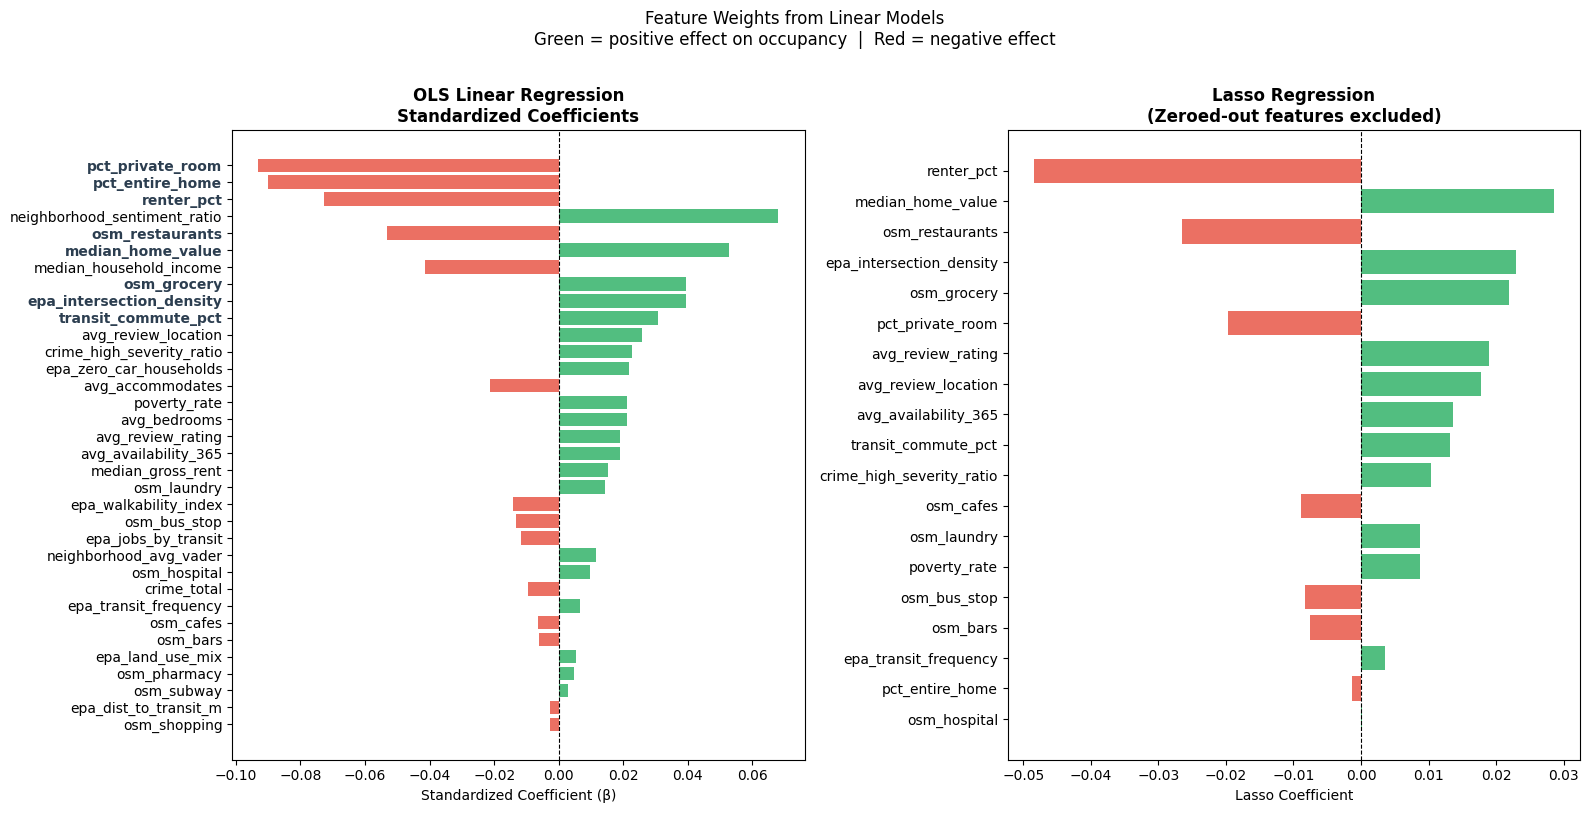

Saved: linear_regression_weights.png


In [37]:
# ── Step 5: Compare OLS vs Lasso vs RF — coefficient chart ──
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# OLS beta coefficients
colors_ols = ['#27AE60' if b > 0 else '#E74C3C' for b in coef_df['beta']]
axes[0].barh(coef_df['feature'][::-1], coef_df['beta'][::-1], color=colors_ols[::-1], alpha=0.8)
axes[0].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_xlabel('Standardized Coefficient (β)')
axes[0].set_title('OLS Linear Regression\nStandardized Coefficients', fontweight='bold')

# Mark significant features
sig_features = coef_df[coef_df['significant']]['feature'].tolist()
yticks = axes[0].get_yticklabels()
for label in yticks:
    if label.get_text() in sig_features:
        label.set_fontweight('bold')
        label.set_color('#2C3E50')

# Lasso coefficients
lasso_nonzero = lasso_df[lasso_df['lasso_coef'] != 0]
colors_lasso = ['#27AE60' if b > 0 else '#E74C3C' for b in lasso_nonzero['lasso_coef']]
axes[1].barh(lasso_nonzero['feature'][::-1], lasso_nonzero['lasso_coef'][::-1], color=colors_lasso[::-1], alpha=0.8)
axes[1].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_xlabel('Lasso Coefficient')
axes[1].set_title('Lasso Regression\n(Zeroed-out features excluded)', fontweight='bold')

plt.suptitle('Feature Weights from Linear Models\nGreen = positive effect on occupancy  |  Red = negative effect',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('./data/linear_regression_weights.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: linear_regression_weights.png')

### 5.5 Scoring Groups
Define the four scoring categories and assign OLS |β| as within-group weights.

In [38]:
# ── Step 6: Use OLS |β| as weights within each scoring group ─
# Build a lookup: feature → absolute standardized coefficient
ols_weight_dict = dict(zip(coef_df['feature'], coef_df['abs_beta']))

# Score groups — same categories, but now weights come from regression
SCORE_GROUPS = {
    'demand_signals': {
        'weight': 0.35,
        'features': ['neighborhood_avg_vader', 'neighborhood_sentiment_ratio',
                     'avg_review_rating', 'avg_review_location']
    },
    'neighborhood_quality': {
        'weight': 0.30,
        'features': ['median_household_income', 'median_home_value',
                     'poverty_rate', 'renter_pct',
                     'crime_per_1000', 'crime_high_severity_ratio']
    },
    'accessibility': {
        'weight': 0.25,
        'features': ['osm_bus_stop', 'transit_commute_pct', 'epa_jobs_by_transit',
                     'epa_dist_to_transit_m', 'epa_walkability_index', 'epa_transit_frequency']
    },
    'amenities': {
        'weight': 0.10,
        'features': ['osm_restaurants', 'osm_cafes', 'osm_grocery',
                     'osm_bars', 'osm_subway', 'osm_pharmacy',
                     'osm_laundry', 'osm_shopping', 'osm_hospital']
    }
}

# Print the effective weights so we can see what changed vs RF
print('=== Effective Within-Group Weights (from OLS |β|) ===')
for group_name, group_config in SCORE_GROUPS.items():
    features = group_config['features']
    raw = {f: ols_weight_dict.get(f, 0.001) for f in features}
    total = sum(raw.values())
    normalized = {f: round(v / total, 3) for f, v in raw.items()}
    print(f'\n  [{group_name}]  (group weight: {group_config["weight"]})')
    for f, w in sorted(normalized.items(), key=lambda x: -x[1]):
        print(f'    {f:40s}  {w:.3f}')


=== Effective Within-Group Weights (from OLS |β|) ===

  [demand_signals]  (group weight: 0.35)
    neighborhood_sentiment_ratio              0.546
    avg_review_location                       0.207
    avg_review_rating                         0.153
    neighborhood_avg_vader                    0.094

  [neighborhood_quality]  (group weight: 0.3)
    renter_pct                                0.344
    median_home_value                         0.249
    median_household_income                   0.195
    crime_high_severity_ratio                 0.107
    poverty_rate                              0.099
    crime_per_1000                            0.005

  [accessibility]  (group weight: 0.25)
    transit_commute_pct                       0.388
    epa_walkability_index                     0.178
    osm_bus_stop                              0.167
    epa_jobs_by_transit                       0.149
    epa_transit_frequency                     0.084
    epa_dist_to_transit_m           

### 5.6 Crime Per Capita Fix
Replace raw `crime_total` with `crime_per_1000_residents` in the scoring model. Raw counts are misleading in dense commercial areas — the Financial District has over 2,000 incidents largely from foot traffic, not residential danger. Per-capita normalization corrects this.


In [ ]:
# Crime per 1000 residents is more meaningful than raw count
# Get population from the already-loaded master table
master['GEOID'] = master['GEOID'].astype(str).str.zfill(11)
master_normalized['GEOID'] = master_normalized['GEOID'].astype(str).str.zfill(11)

pop_crime = master[['GEOID', 'total_population', 'crime_total']].copy()
pop_crime['GEOID'] = pop_crime['GEOID'].astype(str).str.zfill(11)
pop_crime['crime_per_1000'] = (
    pop_crime['crime_total'] /
    pop_crime['total_population'].replace(0, np.nan) * 1000
).fillna(0)

master_normalized = master_normalized.merge(
    pop_crime[['GEOID', 'crime_per_1000']], on='GEOID', how='left'
)

# Update neighborhood_quality group to use per-capita crime
SCORE_GROUPS['neighborhood_quality']['features'] = [
    'median_household_income', 'median_home_value',
    'poverty_rate', 'renter_pct',
    'crime_per_1000',
    'crime_high_severity_ratio'
]

# Normalize and invert the new column
scaler_crime = MinMaxScaler()
master_normalized['crime_per_1000'] = scaler_crime.fit_transform(
    master_normalized[['crime_per_1000']]
)
master_normalized['crime_per_1000'] = 1 - master_normalized['crime_per_1000']

print('crime_per_1000 added and normalized')
print(master_normalized[['GEOID', 'crime_per_1000']].describe())


### 5.7 Composite Investment Score
Two-level weighting:
- **Level 1 (domain knowledge):** Demand Signals 35% · Neighborhood Quality 30% · Accessibility 25% · Amenities 10%
- **Level 2 (data-driven):** OLS |β| coefficients normalized within each group as feature weights

Each city is scored **independently** so Boston tracts are ranked against Boston and SF against SF.


In [40]:
# ============================================================
# BLOCK 1 — City-level scoring (Boston and SF independently)
# ============================================================
from sklearn.preprocessing import MinMaxScaler

def score_city(city_name, master_normalized, importances_df, score_groups):
    city_data = master_normalized[master_normalized["city"] == city_name].copy()
    print(f"\n{'='*50}")
    print(f"Scoring {city_name.upper()} — {len(city_data)} tracts")
    print(f"{'='*50}")

    id_cols = ["GEOID", "city"]
    feature_cols = [c for c in city_data.columns if c not in id_cols]

    city_scaled = city_data.copy()
    scaler = MinMaxScaler()
    city_scaled[feature_cols] = scaler.fit_transform(city_data[feature_cols])

    rf_importance_dict = dict(zip(importances_df["feature"], importances_df["importance"]))
    scored = city_scaled[["GEOID", "city"]].copy()

    for group_name, group_config in score_groups.items():
        features = group_config["features"]
        group_importances = {f: rf_importance_dict.get(f, 0.001) for f in features}
        total = sum(group_importances.values())
        group_weights = {f: v / total for f, v in group_importances.items()}
        group_score = sum(city_scaled[f] * group_weights[f] for f in features)
        scored[f"score_{group_name}"] = group_score.round(4)

    scored["investment_score"] = sum(
        scored[f"score_{group_name}"] * group_config["weight"]
        for group_name, group_config in score_groups.items()
    )

    scored["investment_score_100"] = (
        (scored["investment_score"] - scored["investment_score"].min()) /
        (scored["investment_score"].max() - scored["investment_score"].min()) * 100
    ).round(2)

    scored["rank"] = scored["investment_score_100"].rank(
        ascending=False, method="min"
    ).astype(int)

    return scored

boston_scored = score_city("boston", master_normalized, coef_df.rename(columns={"abs_beta": "importance"}), SCORE_GROUPS)
sf_scored     = score_city("sf",     master_normalized, coef_df.rename(columns={"abs_beta": "importance"}), SCORE_GROUPS)

all_scored = pd.concat([boston_scored, sf_scored], ignore_index=True)
all_scored.to_csv("./data/tract_investment_scores.csv", index=False)
print(f"\nSaved! Total tracts scored: {len(all_scored)}")


Scoring BOSTON — 235 tracts

Scoring SF — 244 tracts

Saved! Total tracts scored: 479


### 5.8 Top 3 Investment Tracts per City

In [ ]:
# Build neighbourhood name map from master table
# (works whether running from Part 1 or starting fresh from Part 2)
if 'neighbourhood_cleansed' in master.columns:
    neighbourhood_map = (
        master[['GEOID', 'neighbourhood_cleansed']]
        .dropna()
        .groupby('GEOID')['neighbourhood_cleansed']
        .agg(lambda x: x.mode()[0])
        .reset_index()
    )
else:
    # Fallback if neighbourhood_cleansed not in master — use GEOID as label
    neighbourhood_map = pd.DataFrame({
        'GEOID': master['GEOID'].unique()
    })
    neighbourhood_map['neighbourhood_cleansed'] = neighbourhood_map['GEOID']

neighbourhood_map['GEOID'] = neighbourhood_map['GEOID'].astype(str).str.zfill(11)

# Merge neighbourhood names into scored results
all_scored['GEOID'] = all_scored['GEOID'].astype(str).str.zfill(11)
results = all_scored.merge(neighbourhood_map, on='GEOID', how='left')
results['neighbourhood_cleansed'] = results['neighbourhood_cleansed'].fillna('Unknown')

display_cols = ['rank', 'GEOID', 'neighbourhood_cleansed', 'investment_score_100',
                'score_demand_signals', 'score_neighborhood_quality',
                'score_accessibility', 'score_amenities']

print('=' * 70)
print('TOP 3 INVESTMENT TRACTS — BOSTON')
print('=' * 70)
boston_top3 = results[results['city'] == 'boston'].sort_values('rank').head(3)
print(boston_top3[display_cols].to_string(index=False))

print('\n' + '=' * 70)
print('TOP 3 INVESTMENT TRACTS — SAN FRANCISCO')
print('=' * 70)
sf_top3 = results[results['city'] == 'sf'].sort_values('rank').head(3)
print(sf_top3[display_cols].to_string(index=False))


### 5.9 Visualize Score Breakdown

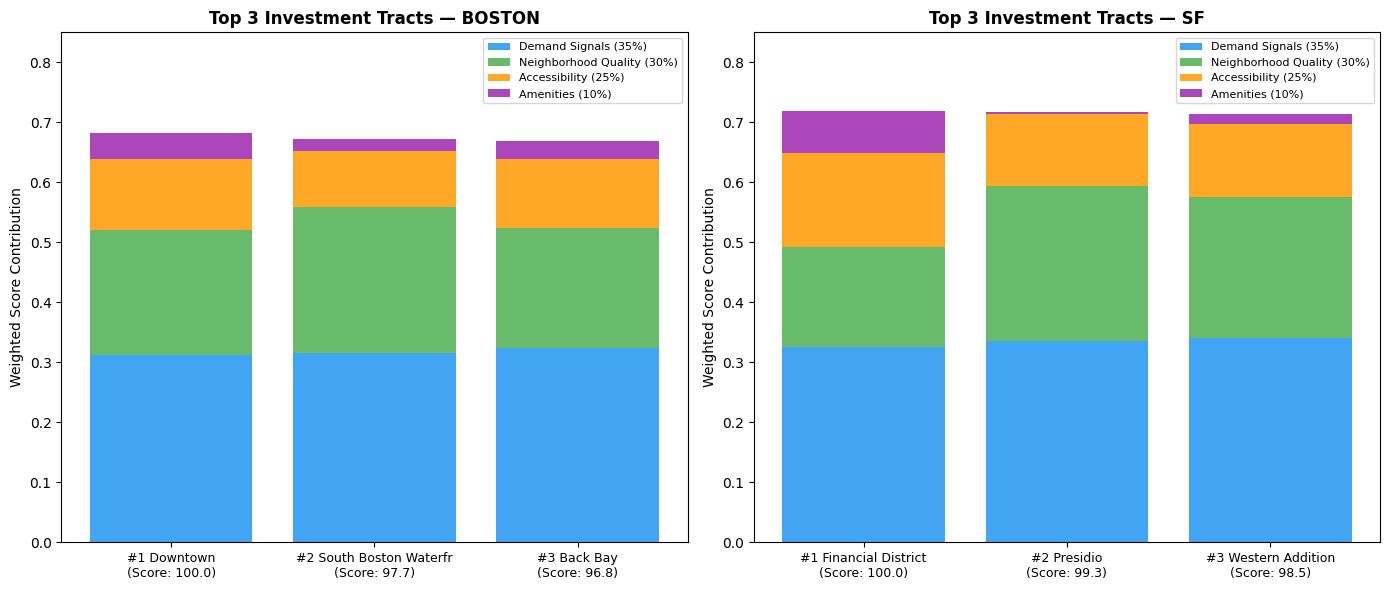

In [42]:
# ============================================================
# BLOCK 3 — Visualize top 3 per city with score breakdown
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

group_cols   = ["score_demand_signals", "score_neighborhood_quality",
                "score_accessibility", "score_amenities"]
group_labels = ["Demand Signals (35%)", "Neighborhood Quality (30%)",
                "Accessibility (25%)", "Amenities (10%)"]
colors = ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0"]

for ax, (city, city_results) in zip(axes, [("BOSTON", boston_top3), ("SF", sf_top3)]):
    tract_labels = [
        f"#{row['rank']} {str(row['neighbourhood_cleansed'])[:20]}\n(Score: {row['investment_score_100']:.1f})"
        for _, row in city_results.iterrows()
    ]

    x = np.arange(3)
    bottom = np.zeros(3)

    for col, label, color, (group_name, group_config) in zip(
        group_cols, group_labels, colors, SCORE_GROUPS.items()
    ):
        values = city_results[col].values * group_config["weight"]
        ax.bar(x, values, bottom=bottom, color=color, label=label, alpha=0.85)
        bottom += values

    ax.set_xticks(x)
    ax.set_xticklabels(tract_labels, fontsize=9)
    ax.set_title(f"Top 3 Investment Tracts — {city}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Weighted Score Contribution")
    ax.legend(fontsize=8, loc="upper right")
    ax.set_ylim(0, 0.85)

plt.tight_layout()
plt.savefig("./data/top3_tracts.png", dpi=150)
plt.show()

### 5.10 Validation — Top Tracts vs City Averages
Cross-check final recommendations against raw unnormalized metrics. Top tracts should outperform city averages on occupancy, income, walkability, and sentiment.

In [ ]:
# Validation: top tracts vs raw metrics
# Use master already loaded in memory
top_geoids = pd.concat([boston_top3, sf_top3])['GEOID'].tolist()
verify = master[master['GEOID'].isin(top_geoids)].copy()

# Merge neighbourhood names
verify = verify.merge(neighbourhood_map, on='GEOID', how='left')
verify['neighbourhood_cleansed'] = verify['neighbourhood_cleansed'].fillna('Unknown')

verify_cols = [
    'neighbourhood_cleansed', 'GEOID',
    'avg_occupancy_rate', 'avg_review_rating', 'avg_review_location',
    'neighborhood_sentiment_ratio', 'neighborhood_avg_vader',
    'median_household_income', 'poverty_rate', 'crime_total',
    'epa_walkability_index', 'osm_bus_stop', 'transit_commute_pct',
    'total_listings', 'pct_entire_home'
]
available = [c for c in verify_cols if c in verify.columns]

print('=== RAW METRICS — TOP 3 BOSTON ===')
boston_verify = verify[verify['GEOID'].isin(boston_top3['GEOID'].tolist())]
print(boston_verify[available].to_string(index=False))

print('\n=== RAW METRICS — TOP 3 SF ===')
sf_verify = verify[verify['GEOID'].isin(sf_top3['GEOID'].tolist())]
print(sf_verify[available].to_string(index=False))

# Compare top 3 vs city average
comparison_cols = ['avg_occupancy_rate', 'median_household_income',
                   'crime_total', 'epa_walkability_index', 'neighborhood_sentiment_ratio']

print('\n=== BOSTON: Top 3 vs City Average ===')
boston_all = master[master['GEOID'].str.startswith('25025')]
for col in comparison_cols:
    if col in boston_all.columns and col in boston_verify.columns:
        print(f'  {col:35s} city avg: {boston_all[col].mean():8.2f} | top 3 avg: {boston_verify[col].mean():8.2f}')

print('\n=== SF: Top 3 vs City Average ===')
sf_all = master[master['GEOID'].str.startswith('06075')]
for col in comparison_cols:
    if col in sf_all.columns and col in sf_verify.columns:
        print(f'  {col:35s} city avg: {sf_all[col].mean():8.2f} | top 3 avg: {sf_verify[col].mean():8.2f}')
